# Week 10 Homework — SNAP **ego-Facebook** 네트워크 분석

**분석 목표**: Facebook 친구 관계 네트워크에서 핵심 노드(허브)를 식별하고, 커뮤니티 구조를 시각화하여 인사이트를 도출한다.

| 항목 | 내용 |
|---|---|
| 데이터셋 | SNAP **ego-Facebook** — `facebook_combined.txt` (McAuley & Leskovec, 2012) |
| 출처 | https://snap.stanford.edu/data/ego-Facebook.html |
| 버전 | `facebook_combined.txt.gz` (SNAP 배포본, 4,039 nodes / 88,234 edges, 익명화된 노드 ID) |
| 분석 환경 | 아래 셀 출력 참고 (Python / OS / 라이브러리 버전) |

In [1]:
import sys, platform, time, os, warnings
warnings.filterwarnings("ignore")

import networkx as nx
import community as community_louvain          # python-louvain
import pyvis
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import pandas as pd
import numpy as np
import scipy
from importlib.metadata import version

env = {
    "Python": sys.version.split()[0],
    "OS": f"{platform.system()} {platform.release()} ({platform.version()})",
    "networkx": nx.__version__,
    "python-louvain": version("python-louvain"),
    "pyvis": version("pyvis"),
    "matplotlib": matplotlib.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scipy": scipy.__version__,
}
pd.DataFrame(env.items(), columns=["항목", "버전/정보"])

,항목,버전/정보
0,Python,3.12.7
1,OS,Windows 11 (10.0.26200)
2,networkx,3.7
3,python-louvain,0.16
4,pyvis,0.3.2
5,matplotlib,3.11.2
6,pandas,3.1.1
7,numpy,2.5.4
8,scipy,1.18.1


In [2]:
# 한글 폰트 및 출력 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.float_format", lambda v: f"{v:.5f}")

SEED = 42
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# 모든 그림을 하나의 PDF에도 모아서 저장
pdf = PdfPages("week10_figures.pdf")
def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")
    pdf.savefig(fig, bbox_inches="tight")

## 1. 데이터 로딩 및 그래프 구성

- `facebook_combined.txt`는 한 줄에 `u v` 형태의 **친구 관계 엣지 리스트**이다.
- Facebook 친구 관계는 상호 관계이므로 **무방향(undirected) 그래프** `nx.Graph`로 구성한다.
- 엣지에 별도의 가중치 정보가 없으므로 **비가중(unweighted)** 그래프로 다룬다 (모든 엣지 weight = 1).

In [3]:
G = nx.read_edgelist("facebook_combined.txt", nodetype=int, create_using=nx.Graph())

n, m = G.number_of_nodes(), G.number_of_edges()
degrees = np.array([d for _, d in G.degree()])
t0 = time.time()
summary = {
    "방향성": "무방향 (Undirected)",
    "가중치": "없음 (Unweighted)",
    "노드 수": n,
    "엣지 수": m,
    "밀도 (density)": round(nx.density(G), 5),
    "평균 차수": round(degrees.mean(), 2),
    "최대 차수": int(degrees.max()),
    "중앙값 차수": float(np.median(degrees)),
    "연결 요소 수": nx.number_connected_components(G),
    "평균 군집 계수": round(nx.average_clustering(G), 4),
    "삼각형 수": sum(nx.triangles(G).values()) // 3,
    "지름 (diameter)": nx.diameter(G),
}
pd.DataFrame(summary.items(), columns=["지표", "값"])

,지표,값
0,방향성,무방향 (Undirected)
1,가중치,없음 (Unweighted)
2,노드 수,4039
3,엣지 수,88234
4,밀도 (density),0.01082
5,평균 차수,43.69000
6,최대 차수,1045
7,중앙값 차수,25.00000
8,연결 요소 수,1
9,평균 군집 계수,0.60550


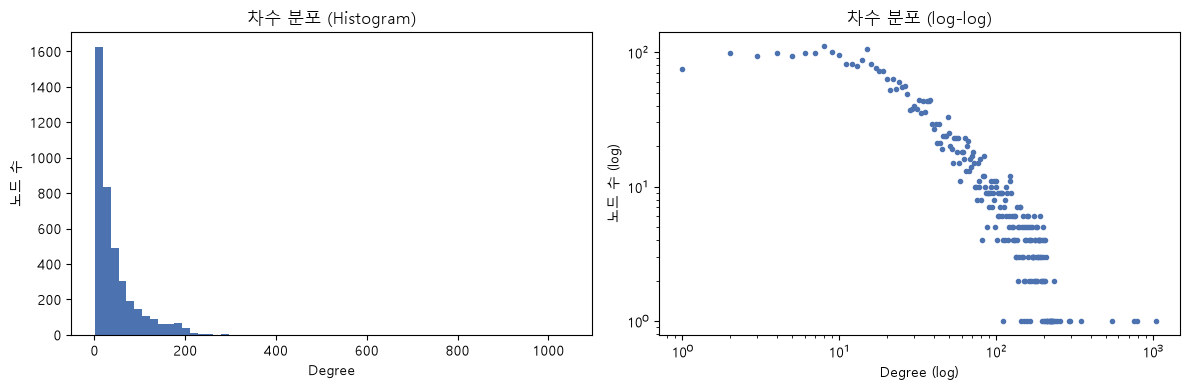

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(degrees, bins=60, color="#4C72B0")
axes[0].set(title="차수 분포 (Histogram)", xlabel="Degree", ylabel="노드 수")

vals, cnts = np.unique(degrees, return_counts=True)
axes[1].loglog(vals, cnts, "o", ms=3, color="#4C72B0")
axes[1].set(title="차수 분포 (log-log)", xlabel="Degree (log)", ylabel="노드 수 (log)")
plt.tight_layout()
save(fig, "01_degree_distribution.png")
plt.show()

### 해석 — 그래프 기본 구조

- **4,039명 / 88,234개 친구 관계**, 연결 요소는 1개로 전체가 하나로 이어져 있다.
- 밀도는 0.0108로 매우 희소하지만, **평균 군집 계수가 0.606**으로 매우 높다 → "내 친구들끼리도 서로 친구"인 전형적인 소셜 네트워크의 특징.
- 평균 차수(43.7)가 중앙값(25)보다 훨씬 크고 최대 차수는 1,045이다. log-log 분포가 오른쪽으로 길게 늘어지는 **heavy-tail** 형태로,
  소수의 허브가 매우 많은 연결을 독점한다.
- 참고: ego-Facebook은 10명의 설문 참여자(ego)의 친구 목록(ego-network)을 합친 데이터이므로, 그 ego들이 자연스럽게 허브가 된다.

## 2. 중심성 분석

| 지표 | 의미 |
|---|---|
| **Degree Centrality** | 직접 연결된 이웃 수 / (n−1). 친구가 많은 노드 |
| **PageRank** | 중요한 노드로부터 연결될수록 높아지는 재귀적 중요도 (α=0.85) |
| **Betweenness Centrality** | 다른 노드 쌍의 최단 경로 위에 얼마나 자주 놓이는지 — 그룹 간 **브로커/다리** 역할 |
| **Eigenvector Centrality** | 영향력 있는 이웃과 연결될수록 높아짐 — 밀집된 핵심 그룹 내부의 중요도 |

Betweenness는 4,039개 노드 전체에 대해 **정확(exact) 계산**한다.

In [5]:
t0 = time.time()
deg_c = nx.degree_centrality(G)
pr    = nx.pagerank(G, alpha=0.85)
eig_c = nx.eigenvector_centrality(G, max_iter=1000)
btw_c = nx.betweenness_centrality(G, normalized=True)
print(f"중심성 계산 시간: {time.time() - t0:.1f}s")

cent = pd.DataFrame({
    "degree": pd.Series(dict(G.degree())),
    "degree_centrality": deg_c,
    "pagerank": pr,
    "betweenness": btw_c,
    "eigenvector": eig_c,
})
cent.index.name = "node"
cent.describe().T

중심성 계산 시간: 115.2s


,count,mean,std,min,25%,50%,75%,max
degree,4039.00000,43.69101,52.42061,1.00000,11.00000,25.00000,57.00000,1045.00000
degree_centrality,4039.00000,0.01082,0.01298,0.00025,0.00272,0.00619,0.01412,0.25879
pagerank,4039.00000,0.00025,0.00026,0.00004,0.00014,0.00022,0.00031,0.00761
betweenness,4039.00000,0.00067,0.01165,0.00000,0.00000,0.00000,0.00002,0.48052
eigenvector,4039.00000,0.00386,0.01525,0.00000,0.00000,0.00000,0.00003,0.09541


In [6]:
def top10(col):
    s = cent[col].sort_values(ascending=False).head(10)
    return pd.DataFrame({"순위": range(1, 11), f"{col}_node": s.index, f"{col}_value": s.values})

top_tables = {c: top10(c) for c in ["degree_centrality", "pagerank", "betweenness", "eigenvector"]}
comparison = pd.concat([t.set_index("순위") for t in top_tables.values()], axis=1)
comparison

,degree_centrality_node,degree_centrality_value,pagerank_node,pagerank_value,betweenness_node,betweenness_value,eigenvector_node,eigenvector_value
순위,,,,,,,,
1,107,0.25879,3437,0.00761,107,0.48052,1912,0.09541
2,1684,0.19614,107,0.00694,1684,0.33780,2266,0.08698
3,1912,0.18697,1684,0.00637,3437,0.23612,2206,0.08605
4,3437,0.13546,0,0.00629,1912,0.22930,2233,0.08517
5,0,0.08593,1912,0.00388,1085,0.14902,2464,0.08428
6,2543,0.07281,348,0.00235,0,0.14631,2142,0.08419
7,2347,0.07207,686,0.00222,698,0.11533,2218,0.08416
8,1888,0.06290,3980,0.00217,567,0.09631,2078,0.08414
9,1800,0.06067,414,0.00180,58,0.08436,2123,0.08367


In [7]:
# 상위 10에 한 번이라도 등장한 노드들의 지표별 순위 비교
ranks = cent[["degree_centrality", "pagerank", "betweenness", "eigenvector"]].rank(ascending=False, method="min").astype(int)
top_union = sorted(set().union(*[set(t.iloc[:, 1]) for t in top_tables.values()]))
rank_cmp = ranks.loc[top_union].assign(degree=cent.loc[top_union, "degree"])
rank_cmp["top10_count"] = (rank_cmp[["degree_centrality", "pagerank", "betweenness", "eigenvector"]] <= 10).sum(axis=1)
rank_cmp.sort_values(["top10_count", "pagerank"], ascending=[False, True])

,degree_centrality,pagerank,betweenness,eigenvector,degree,top10_count
node,,,,,,
1912,3,5,4,1,755,4
3437,4,1,3,2542,547,3
107,1,2,1,757,1045,3
1684,2,3,2,1194,792,3
0,5,4,6,1005,347,3
698,819,10,7,3371,68,2
348,14,6,15,1098,229,1
686,140,7,17,3837,170,1
3980,978,8,20,3208,59,1


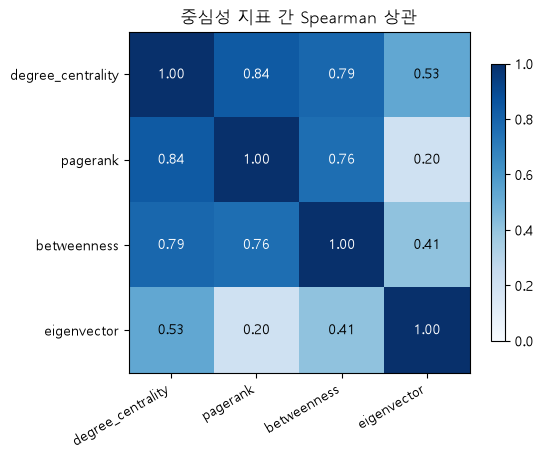

,degree_centrality,pagerank,betweenness,eigenvector
degree_centrality,1.00000,0.83764,0.78814,0.52937
pagerank,0.83764,1.00000,0.75840,0.20204
betweenness,0.78814,0.75840,1.00000,0.40759
eigenvector,0.52937,0.20204,0.40759,1.00000


In [8]:
# 지표 간 상관관계 (Spearman 순위 상관)
corr = cent[["degree_centrality", "pagerank", "betweenness", "eigenvector"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(4), corr.columns, rotation=30, ha="right")
ax.set_yticks(range(4), corr.columns)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if corr.iloc[i, j] > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("중심성 지표 간 Spearman 상관")
save(fig, "02_centrality_correlation.png")
plt.show()
corr

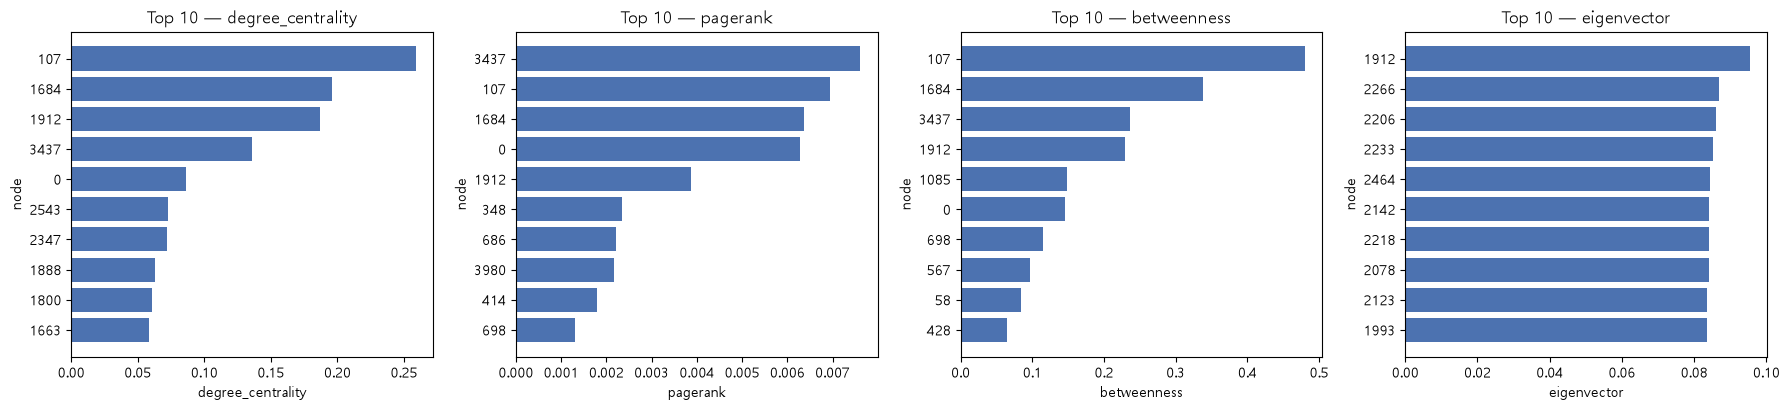

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (col, t) in zip(axes, top_tables.items()):
    ax.barh(t.iloc[::-1, 1].astype(str), t.iloc[::-1, 2], color="#4C72B0")
    ax.set_title(f"Top 10 — {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("node")
plt.tight_layout()
save(fig, "03_centrality_top10.png")
plt.show()

### 해석 — 중심성 비교

1. **세 지표 이상에서 Top 10에 공통으로 등장하는 노드: 107, 1684, 1912, 3437, 0**
   → 연결 수·영향력·중개력을 모두 갖춘 이 네트워크의 핵심 허브이다.
2. **PageRank Top 10 = {3437, 107, 1684, 0, 1912, 348, 686, 3980, 414, 698}** 은 SNAP 원본 데이터의 **10개 ego(설문 참여자) 노드와 정확히 일치**한다.
   ego들은 자기 친구 목록 전체와 연결되어 있고, 그 친구들 중 다수가 다른 곳과는 거의 연결되지 않기 때문에 PageRank가 ego에게 집중된다.
   - 예: **3437**은 차수는 4위(547)지만 PageRank는 1위 — 이웃 대부분이 차수가 낮아 랜덤 워크가 3437로 되돌아올 수밖에 없는 구조.
   - **698**(차수 68), **3980**(차수 59)도 차수 순위는 800~900위권이지만 PageRank는 Top 10 → PageRank는 단순한 친구 수보다 "작은 그룹의 유일한 중심"을 잘 잡아낸다.
3. **Betweenness**: 107(0.48)은 전체 최단 경로의 약 48%가 지나가는 **최대 브로커**이다. 또한 **1085(차수 66), 567(63), 58(12)** 처럼
   차수는 낮지만 서로 다른 그룹을 이어주는 **다리(bridge) 노드**가 Top 10에 등장한다. 특히 58은 친구가 12명뿐이지만 Betweenness 9위이다.
4. **Eigenvector**는 다른 지표와 성격이 전혀 다르다. Top 10 중 1912를 제외한 9개(2266, 2206, 2233, …)가 모두
   **1912 주변의 초고밀도 클러스터(C7, 내부 밀도 0.59)** 에 속한다. Eigenvector는 "잘 연결된 노드들끼리 서로 점수를 올려주는" 구조라서
   가장 밀집된 한 덩어리에 점수가 쏠리는 **국소화(localization)** 현상이 나타난다. 그래서 107·3437 같은 허브의 Eigenvector 순위는 수백~수천 위다.
5. Spearman 상관: Degree–PageRank(0.84), Degree–Betweenness(0.79)는 높지만 **PageRank–Eigenvector는 0.20**에 불과하다.
   → "어떤 의미의 중요도인지"에 따라 지표를 골라야 하며, 하나의 지표만으로 핵심 노드를 판단하면 위험하다.

## 3. 커뮤니티 탐지 및 시각화 (Louvain)

`python-louvain`의 `best_partition`으로 모듈러리티를 최대화하는 커뮤니티를 탐지한다.
Louvain은 노드 방문 순서에 따라 결과가 조금씩 달라지므로 `random_state=42`로 고정하여 재현성을 확보한다.

In [10]:
partition = community_louvain.best_partition(G, random_state=SEED)
modularity = community_louvain.modularity(partition, G)

# 커뮤니티 ID를 크기 순으로 재번호 (0 = 가장 큰 커뮤니티)
raw_sizes = pd.Series(partition).value_counts()
relabel = {old: new for new, old in enumerate(raw_sizes.index)}
partition = {node: relabel[c] for node, c in partition.items()}
cent["community"] = pd.Series(partition)
n_comm = cent["community"].nunique()

print(f"커뮤니티 수: {n_comm}")
print(f"Modularity: {modularity:.4f}")

커뮤니티 수: 15
Modularity: 0.8349


In [11]:
# 커뮤니티별 특성 요약
rows = []
for c, members in cent.groupby("community").groups.items():
    sub = G.subgraph(members)
    internal = sub.number_of_edges()
    total_deg = sum(d for _, d in G.degree(members))
    external = total_deg - 2 * internal
    hub = cent.loc[members, "degree"].idxmax()
    bridge = cent.loc[members, "betweenness"].idxmax()
    rows.append({
        "community": c,
        "노드 수": len(members),
        "비율(%)": 100 * len(members) / n,
        "내부 엣지": internal,
        "외부 엣지": external,
        "내부 밀도": nx.density(sub),
        "평균 군집계수": nx.average_clustering(sub),
        "Conductance": external / total_deg if total_deg else 0,
        "허브(최대 차수)": hub,
        "허브 차수": int(cent.loc[hub, "degree"]),
        "최대 Betweenness 노드": bridge,
    })
comm_df = pd.DataFrame(rows).set_index("community").sort_values("노드 수", ascending=False)
comm_df.style.format({"비율(%)": "{:.1f}", "내부 밀도": "{:.4f}", "평균 군집계수": "{:.3f}", "Conductance": "{:.4f}"})

,노드 수,비율(%),내부 엣지,외부 엣지,내부 밀도,평균 군집계수,Conductance,허브(최대 차수),허브 차수,최대 Betweenness 노드
community,,,,,,,,,,
0,548,13.6,5356,45,0.0357,0.625,0.0042,3437,547,3437
1,535,13.2,8691,479,0.0608,0.516,0.0268,1684,792,1684
2,442,10.9,11591,1244,0.1189,0.623,0.0509,1912,755,1912
3,432,10.7,16677,1258,0.1791,0.585,0.0363,107,1045,107
4,430,10.6,6077,843,0.0659,0.592,0.0649,483,231,567
5,354,8.8,2853,65,0.0457,0.654,0.0113,0,347,0
6,323,8.0,6288,1004,0.1209,0.564,0.0739,917,130,389
7,237,5.9,16543,906,0.5915,0.777,0.0267,2543,294,2543
8,226,5.6,5600,294,0.2203,0.525,0.0256,2839,137,3090


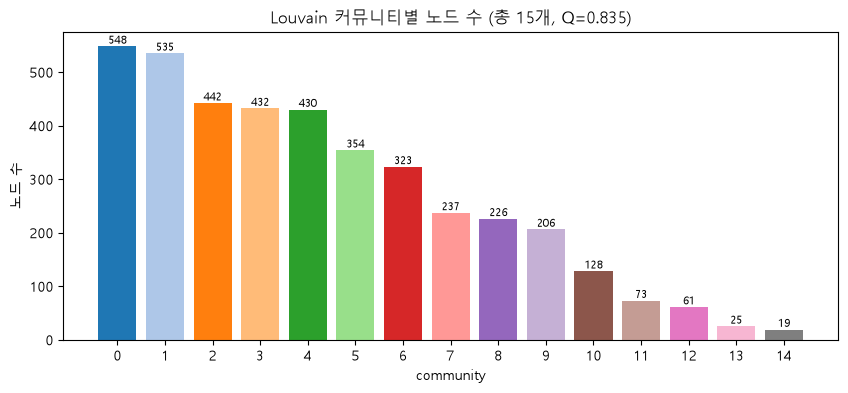

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
cmap = plt.get_cmap("tab20")
ax.bar(comm_df.index.astype(str), comm_df["노드 수"], color=[cmap(c % 20) for c in comm_df.index])
for x, v in zip(comm_df.index.astype(str), comm_df["노드 수"]):
    ax.text(x, v + 5, str(v), ha="center", fontsize=8)
ax.set(title=f"Louvain 커뮤니티별 노드 수 (총 {n_comm}개, Q={modularity:.3f})", xlabel="community", ylabel="노드 수")
save(fig, "04_community_sizes.png")
plt.show()

layout: 68.2s


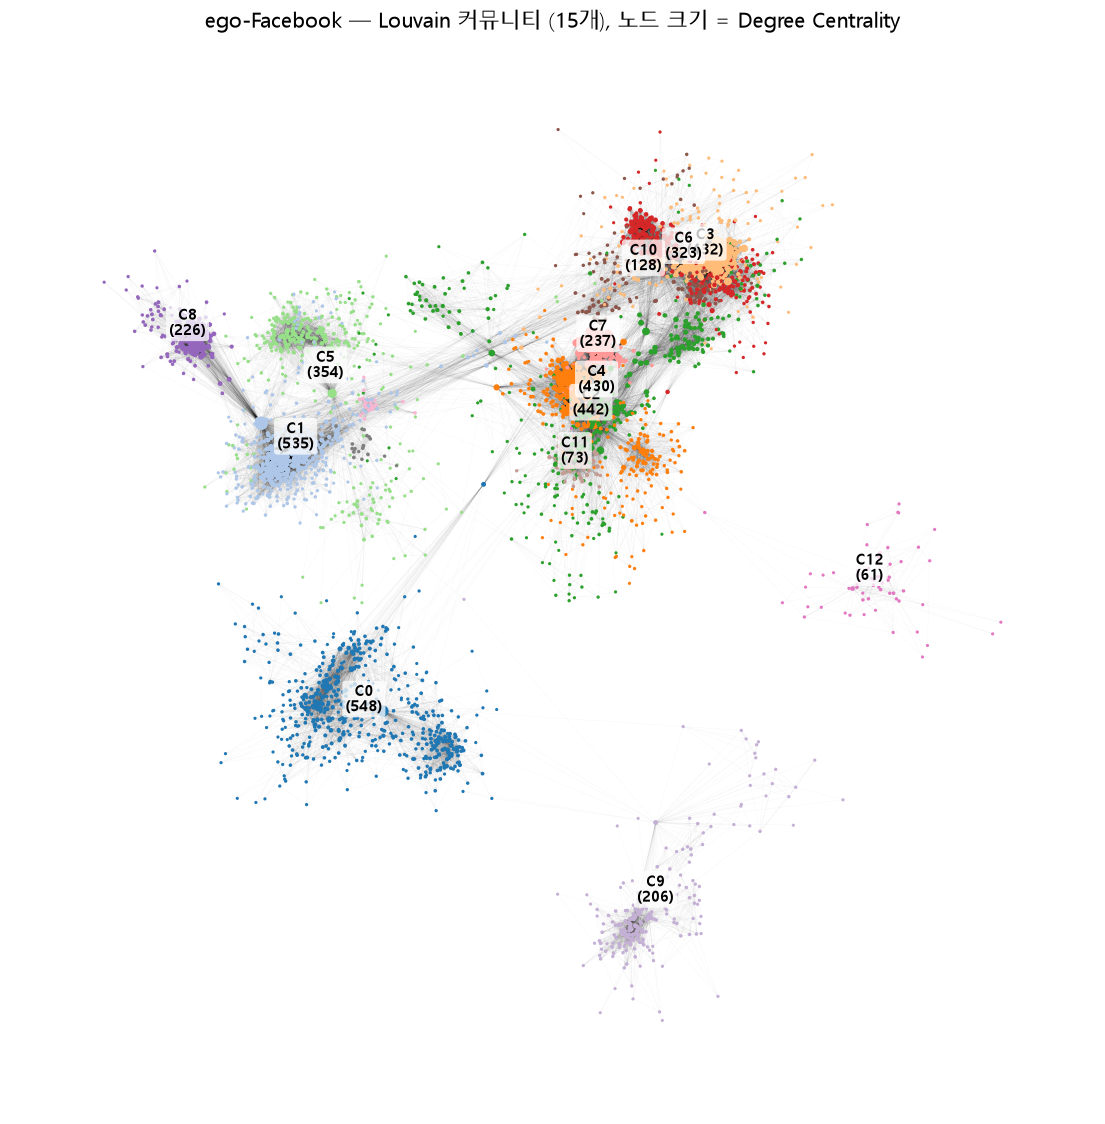

In [13]:
# 전체 네트워크 레이아웃 (spring layout, 시드 고정)
t0 = time.time()
pos = nx.spring_layout(G, k=0.08, iterations=60, seed=SEED)
print(f"layout: {time.time() - t0:.1f}s")

node_colors = [cmap(partition[v] % 20) for v in G.nodes()]
node_sizes = [5 + 120 * (deg_c[v] / max(deg_c.values())) for v in G.nodes()]

fig, ax = plt.subplots(figsize=(14, 14))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.04, width=0.3)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=node_sizes, linewidths=0)

# 커뮤니티 라벨 (중심 좌표)
for c in comm_df.index:
    members = [v for v in G if partition[v] == c]
    if len(members) < 40:
        continue
    xy = np.mean([pos[v] for v in members], axis=0)
    ax.text(*xy, f"C{c}\n({len(members)})", fontsize=11, weight="bold", ha="center",
            bbox=dict(facecolor="white", alpha=0.75, edgecolor="none", boxstyle="round,pad=0.2"))
ax.set_title(f"ego-Facebook — Louvain 커뮤니티 ({n_comm}개), 노드 크기 = Degree Centrality", fontsize=15)
ax.axis("off")
save(fig, "05_community_network.png")
plt.show()

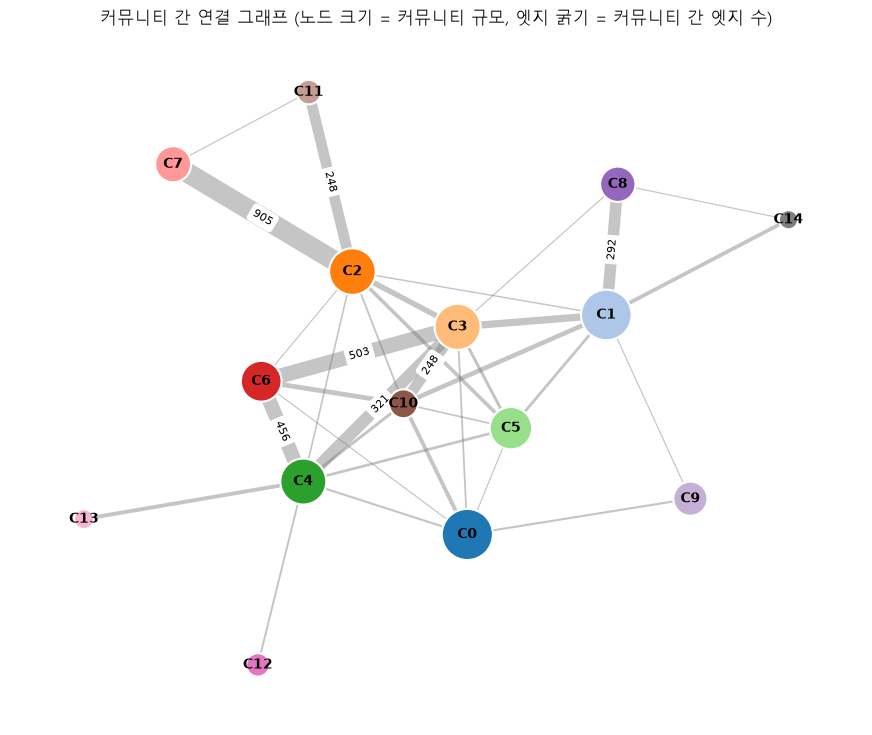

,community_A,community_B,엣지 수
20,2,7,905
13,3,6,503
8,4,6,456
6,4,3,321
25,1,8,292
19,2,11,248
14,3,10,248
15,3,1,108
17,3,2,58
28,6,10,43


In [14]:
# 커뮤니티 간 연결 구조 (커뮤니티 = 노드, 커뮤니티 간 엣지 수 = 엣지 가중치)
CG = community_louvain.induced_graph(partition, G)
CG.remove_edges_from(nx.selfloop_edges(CG))
cpos = nx.kamada_kawai_layout(CG, weight=None)
w = np.array([d["weight"] for _, _, d in CG.edges(data=True)])

fig, ax = plt.subplots(figsize=(11, 9))
nx.draw_networkx_edges(CG, cpos, ax=ax, width=0.4 + 14 * np.sqrt(w / w.max()), alpha=0.45, edge_color="gray")
nx.draw_networkx_nodes(CG, cpos, ax=ax, node_color=[cmap(c % 20) for c in CG.nodes()],
                       node_size=[150 + 2.2 * comm_df.loc[c, "노드 수"] for c in CG.nodes()],
                       edgecolors="white", linewidths=1.5)
nx.draw_networkx_labels(CG, cpos, ax=ax, labels={c: f"C{c}" for c in CG.nodes()}, font_size=10, font_weight="bold")
strong = {(u, v): d["weight"] for u, v, d in CG.edges(data=True) if d["weight"] >= 200}
nx.draw_networkx_edge_labels(CG, cpos, edge_labels=strong, ax=ax, font_size=8)
ax.set_title("커뮤니티 간 연결 그래프 (노드 크기 = 커뮤니티 규모, 엣지 굵기 = 커뮤니티 간 엣지 수)")
ax.axis("off")
save(fig, "06_community_graph.png")
plt.show()

inter = pd.DataFrame([(u, v, d["weight"]) for u, v, d in CG.edges(data=True)],
                     columns=["community_A", "community_B", "엣지 수"]).sort_values("엣지 수", ascending=False)
inter.head(10)

### 해석 — 커뮤니티 구조

- Louvain 결과 **15개 커뮤니티**, **Modularity Q = 0.835**. 일반적으로 Q > 0.3이면 뚜렷한 커뮤니티 구조로 보므로, 매우 강한 모듈 구조를 가진 네트워크이다.
- 커뮤니티 크기는 548명(C0)부터 19명(C14)까지 다양하며, 상위 5개 커뮤니티(C0~C4)가 전체의 약 59%를 차지한다.
- **대부분의 대형 커뮤니티는 하나의 ego 허브를 중심으로 형성**된다: C0 ↔ 3437, C1 ↔ 1684, C2 ↔ 1912, C3 ↔ 107, C5 ↔ 0, C9 ↔ 686.
  즉 Louvain이 찾은 커뮤니티는 대체로 "한 사람의 친구 그룹"에 대응한다.

**주요 커뮤니티 특성**

| 커뮤니티 | 규모 | 허브 | 특징 |
|---|---|---|---|
| **C0** | 548 | 3437 | 가장 크지만 Conductance 0.004 — 외부 연결이 45개뿐인 **고립된 섬**. 3437 한 명이 사실상 유일한 외부 통로 |
| **C1** | 535 | 1684 | 1684 중심 그룹. 위성 커뮤니티 **C8(226명)** 과 292개 엣지로 강하게 연결 |
| **C2** | 442 | 1912 | 1912 중심. **C7과 905개 엣지**(커뮤니티 간 최대 연결)로 묶여 있어 사실상 하나의 큰 그룹 |
| **C3** | 432 | 107 | 내부 엣지 16,677개로 가장 많고, C6·C4·C10과 연결된 **네트워크 중앙부**. 107이 이 영역 전체를 중개 |
| **C7** | 237 | 2543 | **내부 밀도 0.59, 군집계수 0.78** — 구성원의 59%가 서로 직접 친구인 초밀집 그룹 (학급·동아리 같은 폐쇄적 집단으로 추정). Eigenvector 상위 노드가 모두 여기에 있다 |
| **C5** | 354 | 0 | 외부 엣지 65개로 C0처럼 고립도가 높다 |
| **C9 / C12** | 206 / 61 | 686 / 3980 | 외부 엣지가 각각 7개, 5개 — 메인 덩어리와 거의 분리된 작은 ego 그룹 |

- 시각화에서도 중앙부(C2·C3·C4·C6·C7·C10·C11)가 서로 얽혀 있고, C0·C9·C12는 멀리 떨어진 섬처럼 분포한다.

## 4. 부분 네트워크 (Ego-Network) 분석

**선정 기준**: 4개 중심성 지표(Degree, PageRank, Betweenness, Eigenvector) 중 **3개 이상에서 Top 10**에 든 노드.

> 단순히 4개 지표의 순위 평균을 쓰면, Eigenvector 중심성이 노드 1912 주변의 초고밀도 클러스터 하나에 몰려 있어서
> (Eigenvector Top 10 중 9개가 같은 클러스터) 해당 클러스터의 평범한 노드들이 상위로 올라오고
> 107·1684·3437 같은 명백한 허브가 빠지는 왜곡이 생긴다. 따라서 "여러 지표에서 공통적으로 상위"인 노드를 핵심 노드로 본다.

각 노드에 대해 `nx.ego_graph(G, node, radius=1)`로 1-hop 이웃 subgraph를 추출하여 `.png`로 저장한다.

In [15]:
key_nodes = rank_cmp[rank_cmp["top10_count"] >= 3].sort_values("degree", ascending=False).index.tolist()
print("핵심 노드:", key_nodes)
cent.loc[key_nodes, ["degree", "degree_centrality", "pagerank", "betweenness", "eigenvector", "community"]] \
    .join(rank_cmp["top10_count"])

핵심 노드: [107, 1684, 1912, 3437, 0]


,degree,degree_centrality,pagerank,betweenness,eigenvector,community,top10_count
node,,,,,,,
107,1045,0.25879,0.00694,0.48052,0.00026,3,3
1684,792,0.19614,0.00637,0.33780,0.00001,1,3
1912,755,0.18697,0.00388,0.22930,0.09541,2,4
3437,547,0.13546,0.00761,0.23612,0.00000,0,3
0,347,0.08593,0.00629,0.14631,0.00003,5,3


In [16]:
ego_rows = []
for node in key_nodes:
    ego = nx.ego_graph(G, node, radius=1)
    alters = ego.subgraph([v for v in ego if v != node])   # 핵심 노드를 제외한 이웃끼리의 구조
    nb_comms = pd.Series([partition[v] for v in alters]).value_counts()
    ego_rows.append({
        "node": node,
        "소속 커뮤니티": partition[node],
        "이웃 수": alters.number_of_nodes(),
        "이웃 간 엣지": alters.number_of_edges(),
        "ego 밀도": nx.density(ego),
        "지역 군집계수": nx.clustering(G, node),
        "이웃 간 연결요소 수 (ego 제거 후)": nx.number_connected_components(alters),
        "이웃의 커뮤니티 수": len(nb_comms),
        "같은 커뮤니티 이웃 비율(%)": 100 * nb_comms.get(partition[node], 0) / len(alters),
        "이웃 커뮤니티 분포 (상위 4)": ", ".join(f"C{c}:{k}" for c, k in nb_comms.head(4).items()),
    })
ego_df = pd.DataFrame(ego_rows).set_index("node")
ego_df

,소속 커뮤니티,이웃 수,이웃 간 엣지,ego 밀도,지역 군집계수,이웃 간 연결요소 수 (ego 제거 후),이웃의 커뮤니티 수,같은 커뮤니티 이웃 비율(%),이웃 커뮤니티 분포 (상위 4)
node,,,,,,,,,
107,3,1045,26750,0.05086,0.04904,12,8,41.24402,"C3:431, C6:323, C4:141, C10:128"
1684,1,792,14025,0.04718,0.04477,10,6,67.29798,"C1:533, C8:226, C14:19, C5:9"
1912,2,755,30025,0.10785,0.10549,10,5,58.41060,"C2:441, C7:237, C11:73, C4:3"
3437,0,547,4813,0.03576,0.03223,15,3,99.63437,"C0:545, C4:1, C9:1"
0,5,347,2519,0.04747,0.04196,19,4,98.55908,"C5:342, C4:3, C3:1, C2:1"


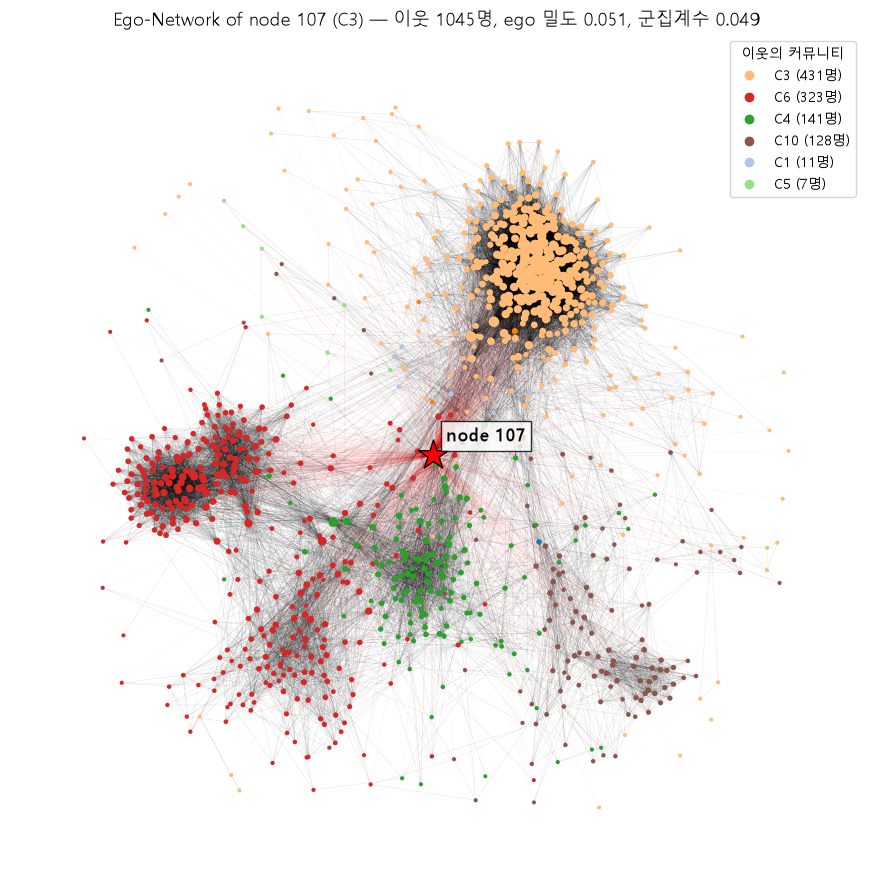

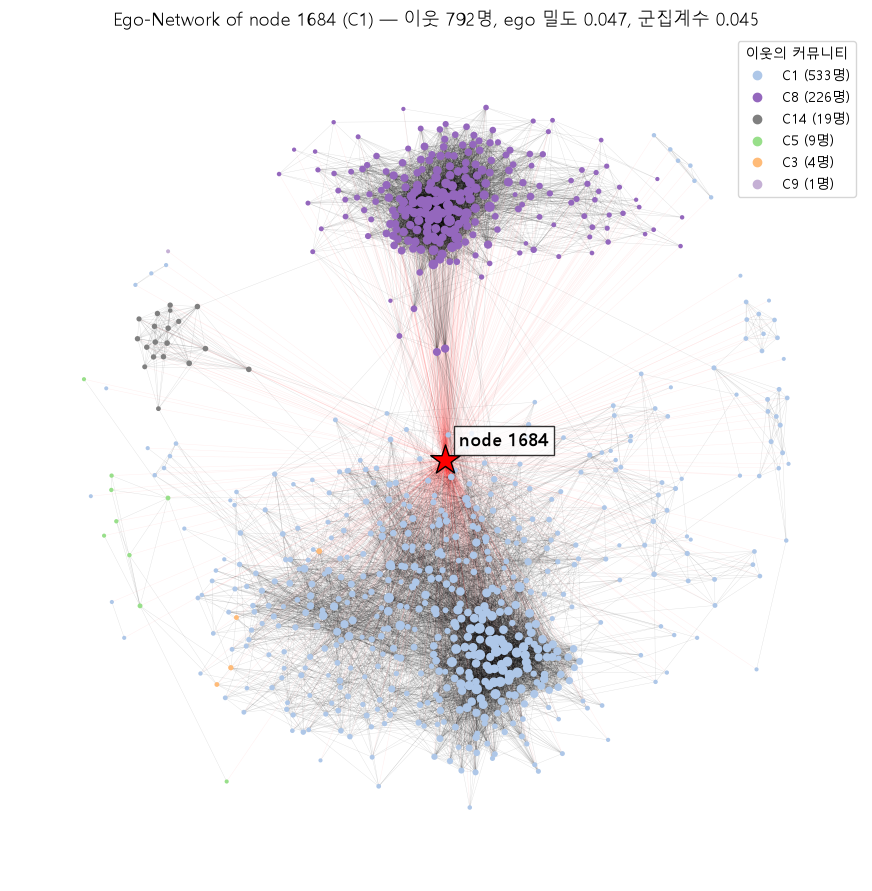

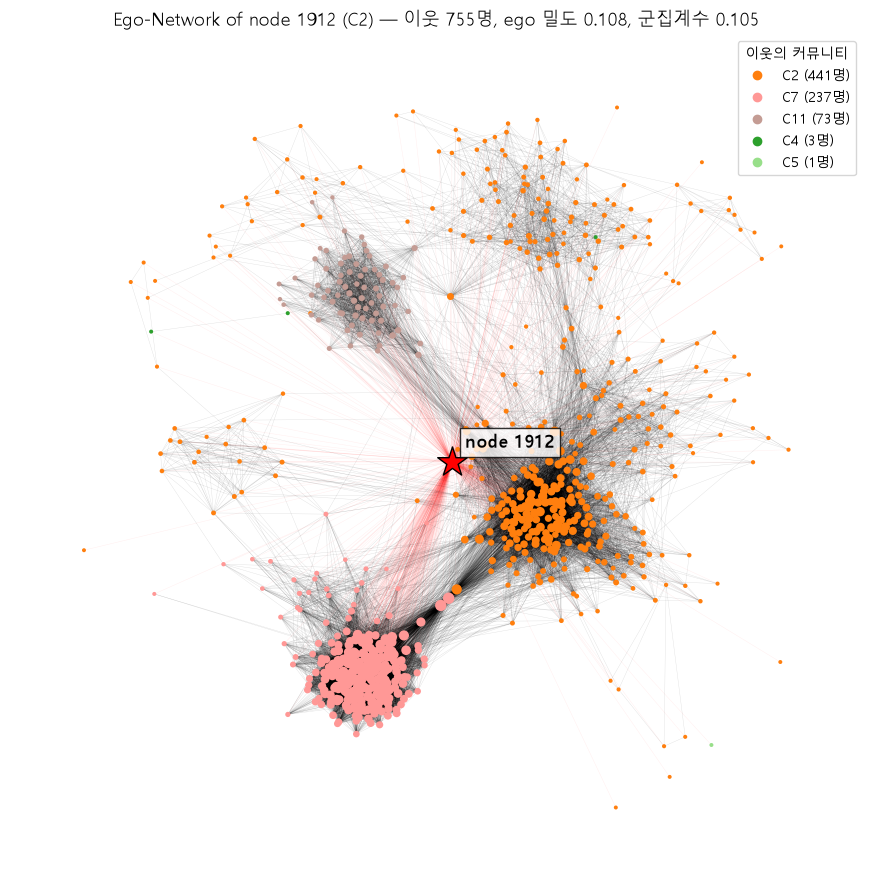

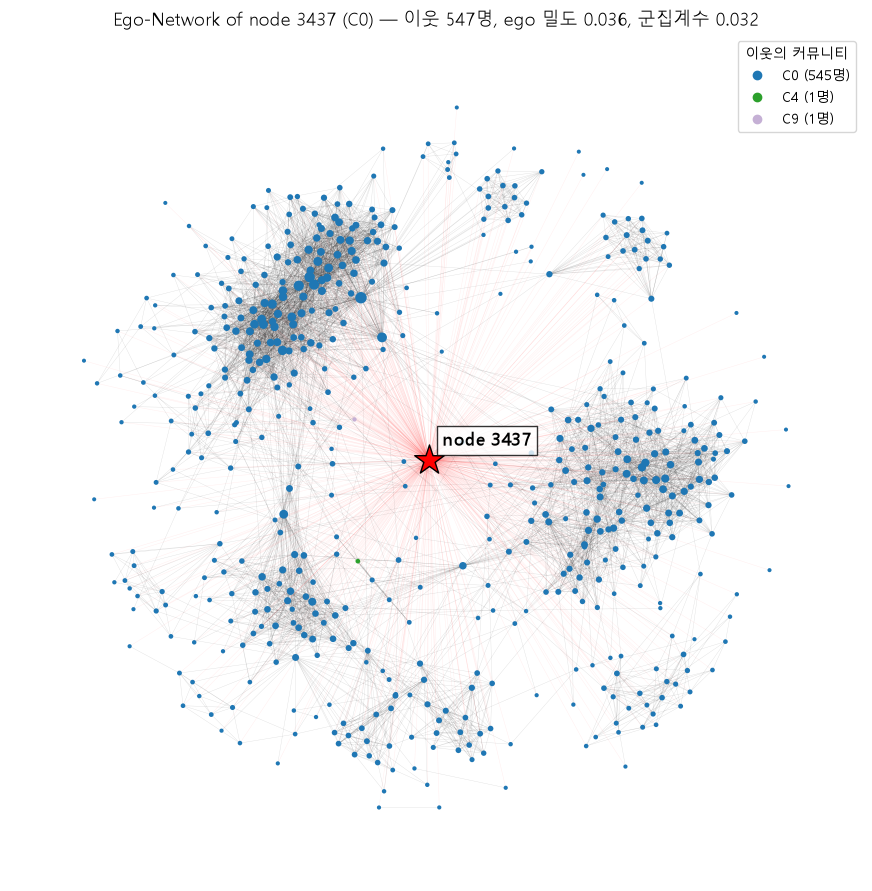

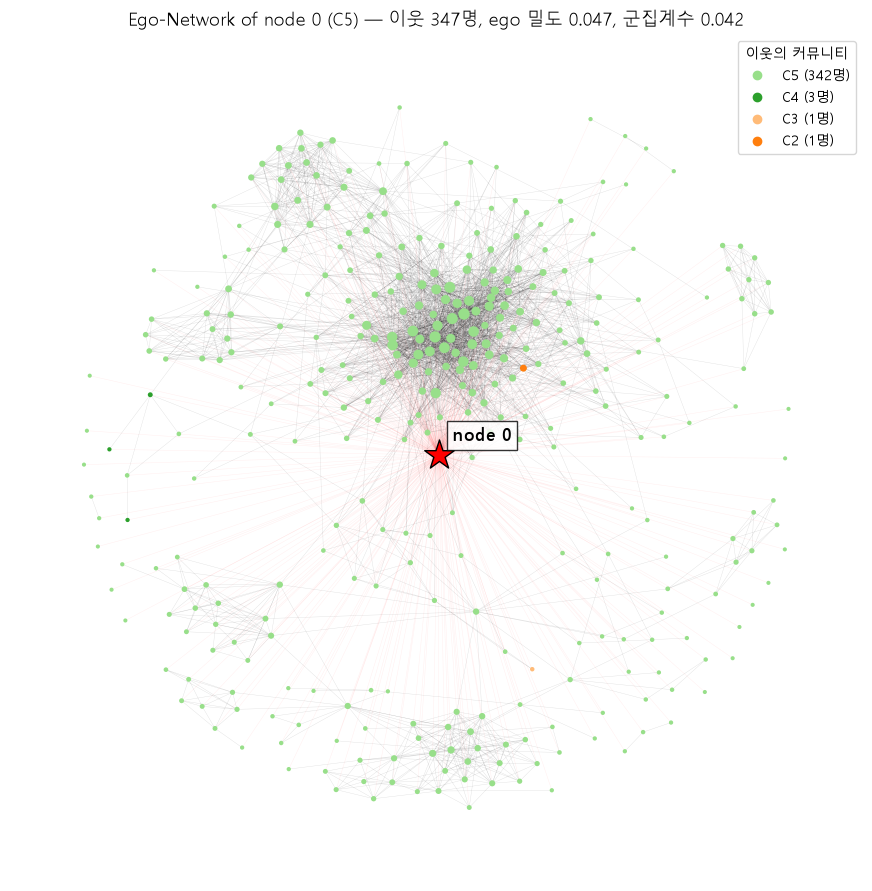

In [17]:
def draw_ego(node):
    ego = nx.ego_graph(G, node, radius=1)
    epos = nx.spring_layout(ego, seed=SEED, k=0.15 if ego.number_of_nodes() > 300 else 0.3, iterations=80)
    others = [v for v in ego if v != node]

    fig, ax = plt.subplots(figsize=(11, 11))
    ego_edges = [(u, v) for u, v in ego.edges() if node in (u, v)]
    alt_edges = [(u, v) for u, v in ego.edges() if node not in (u, v)]
    nx.draw_networkx_edges(ego, epos, edgelist=ego_edges, ax=ax, alpha=0.06, width=0.4, edge_color="red")
    nx.draw_networkx_edges(ego, epos, edgelist=alt_edges, ax=ax, alpha=0.12, width=0.3)
    nx.draw_networkx_nodes(ego, epos, nodelist=others, ax=ax, linewidths=0,
                           node_color=[cmap(partition[v] % 20) for v in others],
                           node_size=[8 + 60 * ego.degree(v) / max(1, max(dict(ego.degree(others)).values())) for v in others])
    nx.draw_networkx_nodes(ego, epos, nodelist=[node], ax=ax, node_color="red", node_size=500,
                           node_shape="*", edgecolors="black")
    ax.annotate(f"node {node}", epos[node], xytext=(10, 10), textcoords="offset points",
                fontsize=13, weight="bold", bbox=dict(facecolor="white", alpha=0.8))

    # 범례: 이웃 커뮤니티 상위 6개
    nb = pd.Series([partition[v] for v in others]).value_counts().head(6)
    handles = [plt.Line2D([], [], marker="o", ls="", color=cmap(c % 20), label=f"C{c} ({k}명)") for c, k in nb.items()]
    ax.legend(handles=handles, title="이웃의 커뮤니티", loc="upper right")
    r = ego_df.loc[node]
    ax.set_title(f"Ego-Network of node {node} (C{partition[node]}) — 이웃 {r['이웃 수']}명, "
                 f"ego 밀도 {r['ego 밀도']:.3f}, 군집계수 {r['지역 군집계수']:.3f}", fontsize=13)
    ax.axis("off")
    save(fig, f"ego_node_{node}.png")
    plt.show()

for node in key_nodes:
    draw_ego(node)

### 해석 — Ego-Network별 핵심 노드의 역할

(표의 "이웃 간 연결요소 수"는 핵심 노드를 제거했을 때 이웃들이 몇 개의 덩어리로 쪼개지는지를 의미한다. 값이 클수록 핵심 노드가 여러 그룹을 묶어주는 역할이 크다.)

- **Node 107 — 네트워크 전체의 최대 브로커 (Bridge Hub)**
  이웃 1,045명이 **8개 커뮤니티**에 걸쳐 있으며(C3 431, C6 323, C4 141, C10 128 …), 자기 커뮤니티 비율은 41%에 불과하다.
  그림에서도 주황(C3)·빨강(C6)·초록(C4)·갈색(C10) 클러스터가 서로 분리된 채 107을 통해 연결된다. 군집계수 0.049로 이웃끼리는 거의 친구가 아니다.
  → Betweenness 1위(0.48)의 원인. 107이 사라지면 네트워크 중앙부의 정보 흐름이 크게 끊긴다.

- **Node 1684 — 두 그룹을 잇는 허브**
  이웃 792명 중 C1이 533명, C8이 226명. 자기 그룹(C1)의 중심이면서 위성 그룹 C8을 메인 네트워크에 연결하는 다리이다.

- **Node 1912 — 밀집 그룹의 중심 (Core Hub)**
  ego 밀도 0.108, 이웃 간 엣지 30,025개로 5개 노드 중 **이웃끼리 가장 촘촘히 연결**되어 있다. 이웃이 C2(441)와 초밀집 그룹 C7(237)에 몰려 있어
  Eigenvector 1위가 되었다. 1912는 "다리"라기보다 영향력 있는 사람들로 둘러싸인 **핵심 그룹의 리더**에 가깝다.

- **Node 3437 — 고립된 그룹의 유일한 관문 (Gatekeeper)**
  이웃 547명 중 **99.6%가 같은 커뮤니티(C0)**. 그러나 이웃 간 연결이 약해(밀도 0.036) 3437을 제거하면 이웃들이 **15개 덩어리**로 쪼개진다.
  그림에서도 여러 개의 작은 하위 그룹이 3437을 중심으로 별(star) 모양으로 매달려 있다. C0 전체의 외부 연결이 45개뿐이라 3437은 C0와 외부 세계를 잇는 관문이며, PageRank 1위를 차지한다.

- **Node 0 — 독립된 친구 그룹의 중심 (Local Star)**
  이웃 347명 중 98.6%가 C5에 속하고, 0을 제거하면 이웃이 **19개 덩어리**로 나뉜다(5개 노드 중 최대). 서로 모르는 여러 소그룹(가족·학교·직장 등)을
  한 사람이 이어주는 전형적인 개인 ego-network 구조이다.

**요약**: 같은 "허브"라도 107·1684는 **커뮤니티 간 다리**, 1912는 **밀집 그룹의 중심**, 3437·0은 **한 커뮤니티 내부의 소그룹들을 묶는 별(star) 중심**으로 역할이 뚜렷하게 구분된다.

## 5. (선택) Pyvis 인터랙티브 시각화

전체 그래프(4,039 노드 / 88,234 엣지)는 브라우저에서 물리 시뮬레이션을 돌리기엔 무겁기 때문에,
위에서 계산한 spring layout 좌표를 고정값으로 넘기고 physics를 끈 상태로 HTML을 생성한다.
노드 색 = Louvain 커뮤니티, 노드 크기 = Degree, 마우스 오버 시 각 중심성 값을 확인할 수 있다.

추가로 핵심 노드 5개와 그 이웃만 포함한 **핵심 허브 subgraph**를 물리 시뮬레이션이 켜진 상태로 별도 생성한다.

In [18]:
from pyvis.network import Network
from matplotlib.colors import to_hex

def node_title(v):
    r = cent.loc[v]
    return (f"node {v}\ncommunity: C{int(r['community'])}\ndegree: {int(r['degree'])}\n"
            f"pagerank: {r['pagerank']:.5f}\nbetweenness: {r['betweenness']:.5f}\neigenvector: {r['eigenvector']:.5f}")

# (1) 전체 네트워크 — 고정 좌표, physics off
net = Network(height="900px", width="100%", bgcolor="#ffffff", cdn_resources="remote")
net.toggle_physics(False)
SCALE = 2500
for v in G.nodes():
    net.add_node(int(v), label=" ", title=node_title(v),
                 color=to_hex(cmap(partition[v] % 20)),
                 size=3 + 25 * deg_c[v] / max(deg_c.values()),
                 x=float(pos[v][0] * SCALE), y=float(pos[v][1] * SCALE))
for u, v in G.edges():
    net.add_edge(int(u), int(v), color="rgba(150,150,150,0.15)", width=0.3)
net.set_options('{"interaction": {"hover": true, "hideEdgesOnDrag": true}, "edges": {"smooth": false}}')
net.write_html("week10_network_interactive.html", notebook=False)

# (2) 핵심 허브 5개 + 이웃 subgraph — physics on
hub_nodes = set(key_nodes)
for k in key_nodes:
    hub_nodes |= set(G.neighbors(k))
H = G.subgraph(hub_nodes)
net2 = Network(height="900px", width="100%", bgcolor="#ffffff", cdn_resources="remote")
for v in H.nodes():
    is_key = v in key_nodes
    net2.add_node(int(v), label=f"{v}" if is_key else " ", title=node_title(v),
                  color="#e41a1c" if is_key else to_hex(cmap(partition[v] % 20)),
                  size=40 if is_key else 4 + 10 * H.degree(v) / max(dict(H.degree()).values()),
                  shape="star" if is_key else "dot")
for u, v in H.edges():
    net2.add_edge(int(u), int(v), color="rgba(150,150,150,0.2)", width=0.3)
net2.barnes_hut(gravity=-8000, spring_length=120)
net2.set_options('{"interaction": {"hover": true, "hideEdgesOnDrag": true}, "edges": {"smooth": false},'
                 ' "physics": {"stabilization": {"iterations": 300}}}')
net2.write_html("week10_hubs_interactive.html", notebook=False)

print("저장 완료:", "week10_network_interactive.html", f"({os.path.getsize('week10_network_interactive.html')/1e6:.1f} MB)")
print("저장 완료:", "week10_hubs_interactive.html", f"({H.number_of_nodes()} nodes, {H.number_of_edges()} edges)")

저장 완료: week10_network_interactive.html (7.8 MB)
저장 완료: week10_hubs_interactive.html (3463 nodes, 81572 edges)


In [19]:
pdf.close()
cent.to_csv("centrality_results.csv")
comm_df.to_csv("community_summary.csv", encoding="utf-8-sig")
print("figures/ 내 PNG:", sorted(os.listdir(FIG_DIR)))
print("PDF:", "week10_figures.pdf")

figures/ 내 PNG: ['01_degree_distribution.png', '02_centrality_correlation.png', '03_centrality_top10.png', '04_community_sizes.png', '05_community_network.png', '06_community_graph.png', 'ego_node_0.png', 'ego_node_107.png', 'ego_node_1684.png', 'ego_node_1912.png', 'ego_node_3437.png']
PDF: week10_figures.pdf


## 6. 결론 및 인사이트

1. **허브 식별**: 107, 1684, 1912, 3437, 0이 여러 중심성 지표에서 공통으로 상위에 있는 핵심 노드다. PageRank Top 10은 데이터 수집 시의 10개 ego 노드와 정확히 일치하여, PageRank가 "각 그룹의 중심 인물"을 잘 찾아냄을 확인했다.
2. **지표별 관점 차이**: Degree·PageRank·Betweenness는 대체로 비슷한 허브를 가리키지만, Betweenness는 차수가 작은 **다리 노드(58, 567, 1085)** 를 추가로 찾아내고, Eigenvector는 가장 밀집된 한 그룹(C7)에 점수가 쏠린다. 목적(영향력 전파 / 정보 중개 / 핵심 그룹 파악)에 맞는 지표를 선택해야 한다.
3. **커뮤니티 구조**: Modularity 0.835의 매우 강한 커뮤니티 구조이며, 대부분의 커뮤니티는 한 ego의 친구 그룹에 대응한다. C0·C5·C9·C12처럼 외부와 거의 단절된 그룹은 **단일 허브에 대한 의존도가 매우 높다**.
4. **활용 관점**: 정보 확산(마케팅·공지)을 위해서는 107·1684 같은 **브로커**를 공략하는 것이 효과적이고, 특정 그룹 내부의 영향력 파악에는 1912 같은 **밀집 그룹의 중심**이 중요하다. 반대로 3437·0 같은 관문 노드가 이탈하면 해당 그룹 전체가 네트워크에서 떨어져 나가는 **취약점**이 된다.

### 제출 산출물
| 파일 | 내용 |
|---|---|
| `week10_homework.ipynb` | 본 분석 노트북 |
| `week10_homework.pdf` | 노트북 PDF 버전 |
| `figures/*.png` | 차수 분포, 중심성 비교, 커뮤니티 시각화, Ego-network 5개 |
| `week10_figures.pdf` | 모든 시각화를 모은 PDF |
| `week10_network_interactive.html` | (Pyvis) 전체 네트워크 인터랙티브 시각화 |
| `week10_hubs_interactive.html` | (Pyvis) 핵심 허브 5개 + 이웃 인터랙티브 시각화 |
| `centrality_results.csv`, `community_summary.csv` | 중심성/커뮤니티 결과 데이터 |